# Exploring the Data

Ideas:
* Names:
    - Seeing consistent clients throughout time (monthly)
    - Summing over hourly and seeing change of demand per hour
* Postal code:
    - Distribution of zipcodes (Map)
    - Change in clusters throughout time (monthly/hourly)
* Numbers:
    - Change number of seniors/adults/youth/babies supported throughout time (monthly)
    - Sum of all numbers
        * Seeing that change over time as well
* Household:
    - Comparing if sum of numbers == household size
* Gender:
    - Distribution (in general and temporal- monthly/hourly)
* Overall:
    - Predicting demand (Regression - Pytorch)
    - Client clusters (KMeans)



In [133]:
##### Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os, json, folium
from folium.plugins import HeatMap


DATA_PATH = os.path.join(
    os.getcwd(),
    'Data'
)

In [134]:
##### Preparing data
df = pd.read_csv(
    f'{DATA_PATH}/food_clean.csv',
    parse_dates=['conversion_date']
)

#### Creating month and hourly variables
df['month'] = df['conversion_date'].dt.month
df['hour'] = df['conversion_date'].dt.hour

#### Summing up individual numbers of populations
population_cols = [col for col in df.columns if col.startswith('number')]
df['number_household_sum'] = df[population_cols[0]] + \
    df[population_cols[1]] + \
    df[population_cols[2]] + \
    df[population_cols[3]]

#### Quantitative and Qualitative Variables
quant_vars = [col for col in df.columns if col.startswith('number')]
qual_vars = list(set(df.columns) - set(quant_vars))


,number_of_seniors,number_of_adults,number_of_youth,number_of_babies,number_household_sum
count,912.000000,912.000000,912.000000,912.000000,912.000000
mean,1.130482,2.086623,1.282895,0.570175,5.070175
std,1.373048,1.342605,1.374463,1.089572,3.516233
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,0.000000,0.000000,2.000000
50%,1.000000,2.000000,1.000000,0.000000,4.000000
75%,2.000000,3.000000,2.000000,1.000000,7.000000
max,5.000000,5.000000,5.000000,5.000000,20.000000


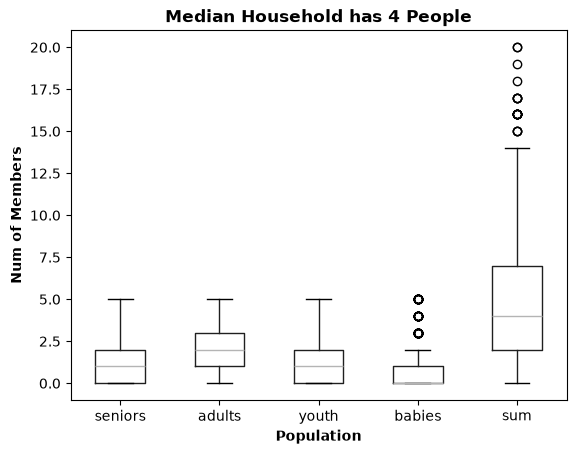

In [135]:
##### General distributions - Quant variables
### Normalizing quant_vars
# df_quant_norm = (
#     df[quant_vars] - df[quant_vars].mean()
# )/df[quant_vars].std(ddof=0)

### Statistics
display(df[quant_vars].describe())
### Box and Whisker
boxplot = df.boxplot(
    column=quant_vars, 
    grid=False,
)
## X Axis
boxplot.set_xticklabels(
    [col.split("_")[-1] for col in quant_vars]
)
boxplot.set_xlabel("Population", fontweight='bold')
## Y Axis
boxplot.set_ylabel("Num of Members", fontweight='bold')
## Title
boxplot.set_title('Median Household has 4 People', fontweight='bold')
plt.show()

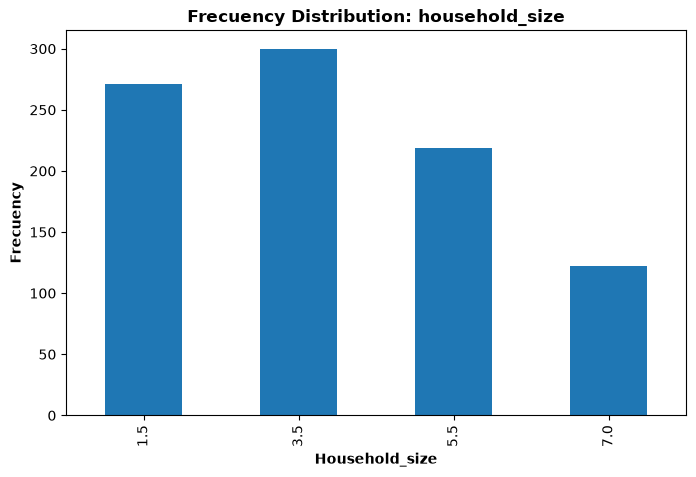

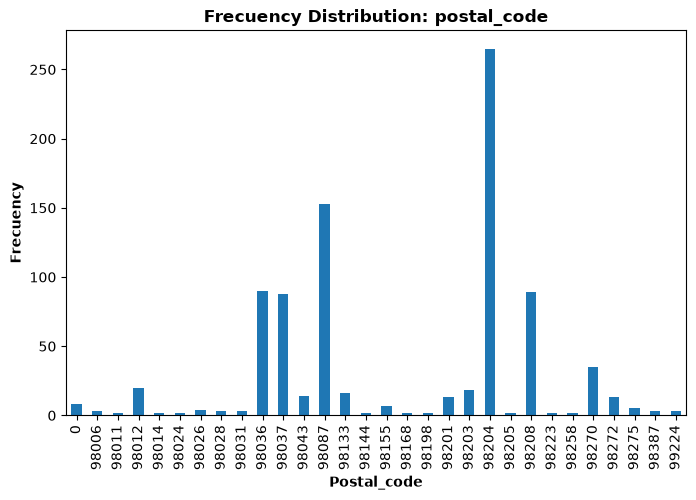

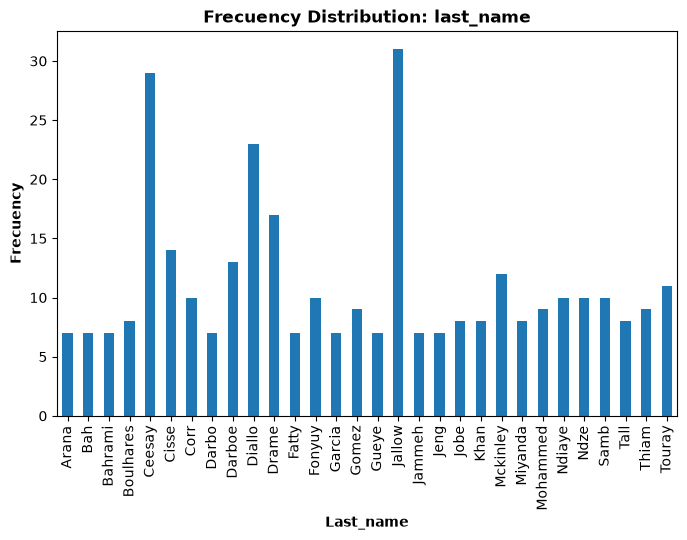

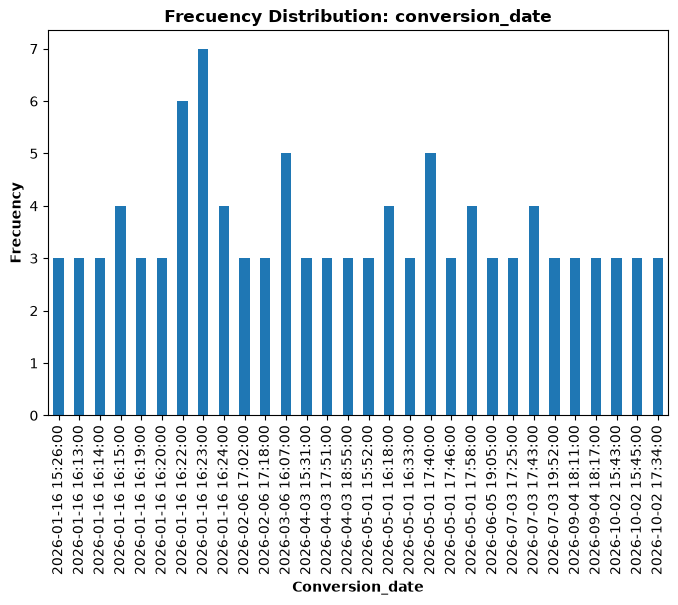

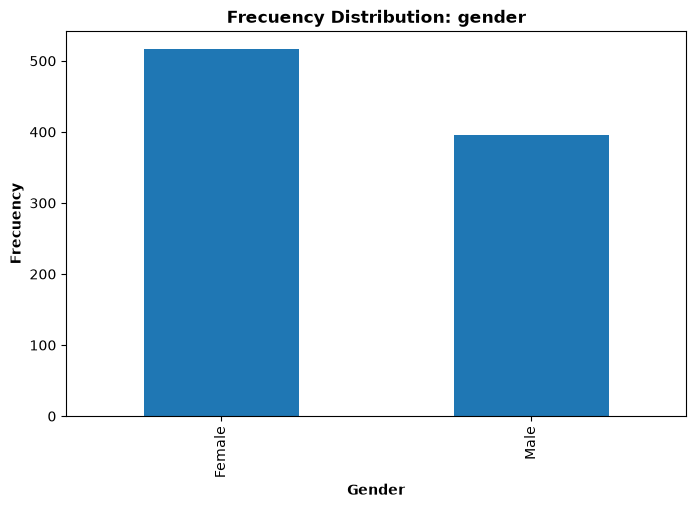

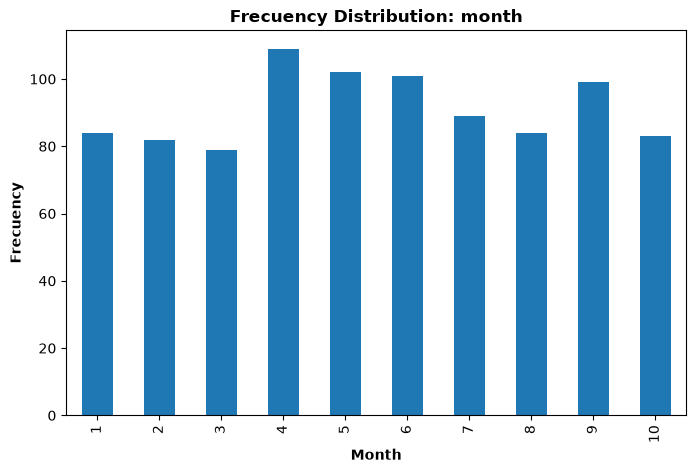

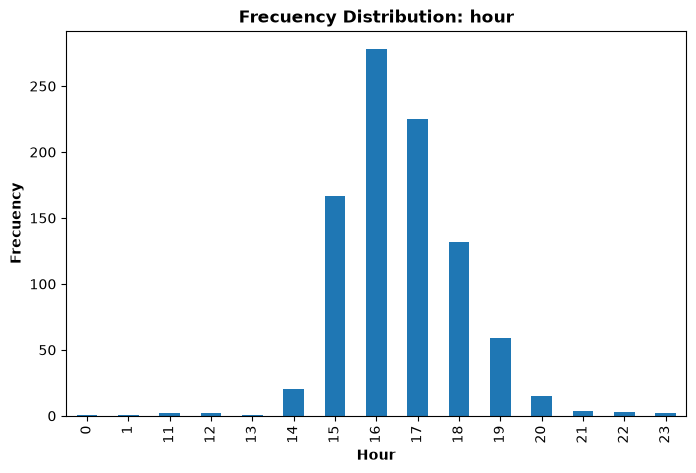

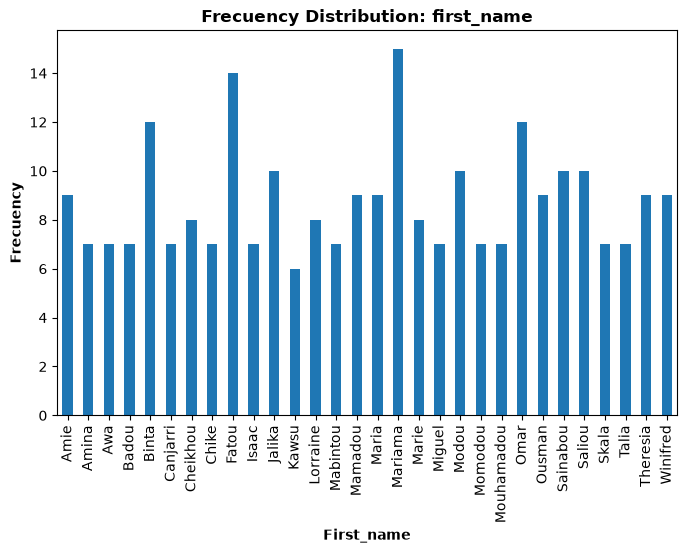

In [136]:
##### Distribution - qual_vars
for col in qual_vars:
    qual_nums = df[col].value_counts()[:30]
    qual_nums = qual_nums.sort_index()
    # print(qual_nums)
    ax = qual_nums.plot.bar(
        figsize=(8,5)
    )
    ax.set_xlabel(col.capitalize(), fontweight='bold')
    ax.set_ylabel('Frecuency', fontweight='bold')
    ax.set_title(
        f'Frecuency Distribution: {col}',
        fontweight='bold'
    )
    plt.show()

In [137]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 912 entries, 0 to 911
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   first_name            912 non-null    str           
 1   last_name             912 non-null    str           
 2   postal_code           912 non-null    int64         
 3   number_of_seniors     912 non-null    int64         
 4   number_of_adults      912 non-null    int64         
 5   number_of_youth       912 non-null    int64         
 6   number_of_babies      912 non-null    int64         
 7   household_size        912 non-null    float64       
 8   gender                912 non-null    str           
 9   conversion_date       912 non-null    datetime64[us]
 10  month                 912 non-null    int32         
 11  hour                  912 non-null    int32         
 12  number_household_sum  912 non-null    int64         
dtypes: datetime64[us](1), float64(1

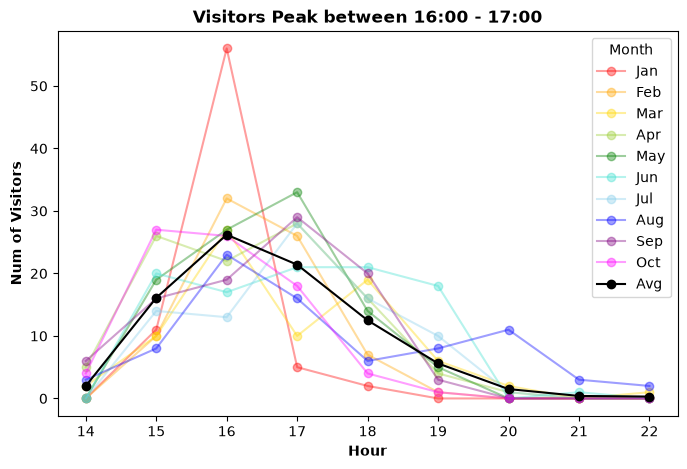

In [138]:
##### First Name
# * Names:
#     - Seeing consistent clients throughout time (monthly)
#     - Summing over hourly and seeing change of demand per hour

#### Consistent clients
df_consistent_clients = df.groupby(
    by=['first_name','last_name'],
    as_index=False
).agg(
    num_months_visited = pd.NamedAgg(
        column='month',
        aggfunc=lambda series: series.nunique()
    ),
    household_sum = pd.NamedAgg(
        column='number_household_sum',
        aggfunc=lambda series: series.mean().round(2)
    )
).sort_values(
    by='num_months_visited',
    # by='household_sum',
    ascending=False
)

# display(df_consistent_clients)





#### Change of demand per hour
df_monthly_hour_change = df.groupby(
    by=['month','hour'],
    as_index=False
).agg(
    num_clients = pd.NamedAgg(
        column='first_name',
        aggfunc= lambda series: series.nunique()
    )
).sort_values(
    by=['month','hour'],
    ascending=[True,True]
)

#### Dropping outliers
    # Registrations at the following hours occured 1/2 times:
        # 0,1,11,12,13,23
df_monthly_hour_change = df_monthly_hour_change[
    ~df_monthly_hour_change['hour'].isin([0,1,11,12,13,23])
]

#### Ensuring all months have the same hours
all_months =df_monthly_hour_change['month'].unique()
all_hours = df_monthly_hour_change['hour'].unique()
full_index = pd.MultiIndex.from_product(
    [all_months, all_hours],
    names=['month','hour']
)
df_complete_m_h_change = df_monthly_hour_change\
    .set_index(['month', 'hour'])\
    .reindex(full_index, fill_value=0)\
    .reset_index()\
    .sort_values(
        by=['month','hour'],
        ascending=[True,True]
    )

df_avg_per_hour = df_complete_m_h_change\
    .groupby(
        by='hour',
        as_index=False
    ).agg(
        avg_clients = pd.NamedAgg(
            column='num_clients',
            aggfunc= lambda series: series.mean()
        )
    ).sort_values(
        by='hour',
        ascending=True
    )

# display(df_complete_m_h_change)
# display(df_avg_per_hour)

#### Visualization
ANCH = 8
ALT = 5
fig, ax = plt.subplots(figsize=(ANCH,ALT))
num_unique_hours = np.arange(len(all_hours))
num_unique_months = np.arange(len(all_months))
months=[
    'Jan', 'Feb', 'Mar', 'Apr', 'May',
    'Jun', 'Jul', 'Aug', 'Sep', 'Oct'
]
colors = [
    "red",          # Enero
    "orange",       # Febrero
    "gold",         # Marzo
    "yellowgreen",  # Abril
    "green",        # Mayo
    "turquoise",    # Junio
    "skyblue",      # Julio
    "blue",         # Agosto
    "purple",       # Septiembre
    "magenta",      # Octubre
    "brown",        # Noviembre
    "gray"          # Diciembre
]
### All months
for month_num in num_unique_months:
    ax.plot(
        num_unique_hours,
        df_complete_m_h_change[
            df_complete_m_h_change['month'] == (month_num + 1)
        ]['num_clients'],
        label = months[month_num],
        color= colors[month_num],
        marker='o',
        alpha=0.38
    )
### Average of clients per hour
ax.plot(
    num_unique_hours,
    df_avg_per_hour["avg_clients"],
    label = 'Avg',
    color = 'black',
    marker='o'
)
### Configs
ax.set_ylabel('Num of Visitors', fontweight='bold')
ax.set_xlabel('Hour', fontweight='bold')
ax.set_xticks(num_unique_hours)
ax.set_xticklabels([str(v) for v in np.sort(all_hours)])
ax.legend(
    title='Month'
)
ax.set_title(
    'Visitors Peak between 16:00 - 17:00',
    fontweight='bold'    
)
plt.show()



In [139]:
# ##### Postal code: from zipcodes -> (long, lat)
# #### Gathering the zipcodes with 4+ people from it
# ds_zipcodes_frec = df['postal_code']\
#     .value_counts()\
#     .sort_values(ascending=False)
# ds_zip_4plus = ds_zipcodes_frec[ds_zipcodes_frec > 3]
# ds_zip_4plus = ds_zip_4plus[ds_zip_4plus.index != 0]
# zipcodes = ds_zip_4plus.index.unique().to_list()

# #### Coordinates
# from geopy.geocoders import Nominatim
# import time, json, os
# geolocator = Nominatim(user_agent="zip_to_coords")

# def get_lat_lon(zipcode):
#     try:
#         location = geolocator.geocode({"postalcode": zipcode, "country": "US"})
#         if location:
#             return location.latitude, location.longitude
#     except Exception as e:
#         print(f"Error con {zipcode}: {e}")
#     return None, None

# latitudes = []
# longitudes = []
# for z in zipcodes:
#     lat, lon = get_lat_lon(z)
#     latitudes.append(lat)
#     longitudes.append(lon)
#     time.sleep(1)

# zip_lat_long_dict = {
#     'zipcodes': zipcodes,
#     'latitudes': latitudes,
#     'longitudes': longitudes
# }

#### Saving results
# with open(f'{DATA_PATH}/zipcodes.json', 'w', encoding='utf-8') as f:
#     json.dump(zip_lat_long_dict, f)

In [ ]:
##### Zipcode Maps 
#### Loading zipcode results
with open(f'{DATA_PATH}/zipcodes.json', 'r', encoding='utf-8') as f:
    zip_lat_long_dict = json.load(f)

#### Recording num of visitors in each zipcode
ds_zipcodes_frec = df['postal_code']\
    .value_counts()\
    .sort_values(ascending=False)

### Finding min and max values
max_visitors = max(ds_zipcodes_frec.values)
min_visitors = min(ds_zipcodes_frec.values)
normalized_frec = (
    ds_zipcodes_frec.values - min_visitors
) / (max_visitors - min_visitors)

zip_lat_lon_frec = [
    [float(lat), float(lon), float(frec)]
    for lat, lon, frec in zip(
        zip_lat_long_dict['latitudes'],
        zip_lat_long_dict['longitudes'],
        normalized_frec.tolist()
    )
]


#### Map - Starting at WAWAC
### Setup
WAWAC_coord = [47.82475860217822, -122.27986001122355]
map = folium.Map(
    location=WAWAC_coord,
    zoom_start=13,
)
folium.Marker(
    location=WAWAC_coord,
    popup='WAWAC',
    icon=folium.Icon(icon="star", prefix="fa", color="orange")
).add_to(map)

### Heatmap for visitor gradient
custom_gradient = {
    0.0: '#0000ff',  
    0.5: '#00ff00', 
    1.0: '#ff0000'   
}
HeatMap(
    zip_lat_lon_frec,
    gradient=custom_gradient,
    min_opacity=0.01,
    radius=25,
    blur=20
).add_to(map)

### Plotting selected zipcodes
for zipcode, lat, lon in zip(
    zip_lat_long_dict['zipcodes'],
    zip_lat_long_dict['latitudes'],
    zip_lat_long_dict['longitudes']
):    
    frecuency = ds_zipcodes_frec.loc[zipcode]
    folium.Marker(
        location=[lat, lon],
        # tooltip=folium.Tooltip(f"{zipcode}:{frecuency}", permanent=True),
        # icon=folium.Icon(
        #     icon="asdsa", 
        #     prefix="fa", 
        #     color="orange",

        # ),
        icon=folium.DivIcon(
            html=f'''
            <div style="
                display: inline-block;
                background-color: white;
                padding: 5px 10px;
                border: 1px solid black;
                border-radius: 5px;
                font-size: 8pt;
                color: black;
                white-space: nowrap;
                box-shadow: 2px 2px 5px rgba(0,0,0,0.3);
            ">
                {zipcode} -- {frecuency}
            </div>
            '''
        )
    ).add_to(map)




map.save(f'{DATA_PATH}/map.html')

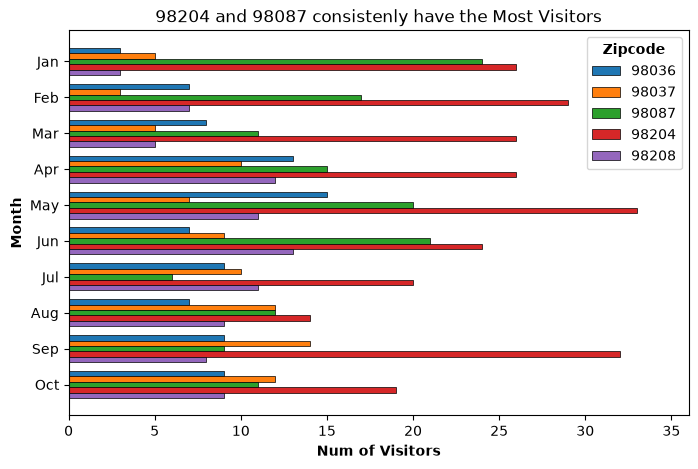

In [ ]:
# * Postal code:
#     - Distribution of zipcodes (Map)
#     - Change in clusters throughout time (monthly/hourly)

#### Gathering top X zipcodes
top_X = 5
top_X_zipcodes = df['postal_code']\
    .value_counts()\
    .sort_values(ascending=False)\
    [:top_X].index.to_list()

#### 
df_clients_per_zip = df.groupby(
    by=['month', 'postal_code'],
    as_index=False
).agg(
    num_clients = pd.NamedAgg(
        column='first_name',
        aggfunc= lambda series: series.nunique()
    )
).sort_values(
    by=['month', 'num_clients'],
    ascending=[True, False]
)

#### Ensuring all months have the same zipcodes
all_months =df_clients_per_zip['month'].unique()
all_zips = top_X_zipcodes
full_index = pd.MultiIndex.from_product(
    [all_months, all_zips],
    names=['month','postal_code']
)
df_complete_client_per_zip = df_clients_per_zip\
    .set_index(['month', 'postal_code'])\
    .reindex(full_index, fill_value=0)\
    .reset_index()\
    .sort_values(
        by=['month','num_clients'],
        ascending=[True,False]
    )

#### Bar graph
### Pivot table
pivot_df = df_complete_client_per_zip.pivot(index='month', columns='postal_code', values='num_clients')
### Initial configs
center = list(range(-1*int(top_X/2),int(top_X/2),1))\
    if top_X % 2 == 0 else\
    list(range(-1*int(top_X/2),int(top_X/2) + 1,1))
months = pivot_df.index
zipcodes = pivot_df.columns
bar_height = 0.15  # grosor de cada barra
y_positions = np.arange(len(months))
### Creating plot
fig, ax = plt.subplots(figsize=(8, 5))
for i, zipcode in enumerate(zipcodes):
    ax.barh(
        y_positions + center[i] * bar_height,  # desplazamiento vertical
        pivot_df[zipcode],
        height=bar_height,
        label=f"{zipcode}",
        edgecolor='black',
        linewidth=0.5,
    )
### Configs finales
ax.invert_yaxis()
ax.set_xlim(0,36)
ax.set_xlabel('Num of Visitors', fontweight='bold')
ax.set_yticks(y_positions)
months=[
    'Jan', 'Feb', 'Mar', 'Apr', 'May',
    'Jun', 'Jul', 'Aug', 'Sep', 'Oct'
]
ax.set_yticklabels(months)
ax.set_ylabel('Month', fontweight='bold')
legend = ax.legend(title='Zipcode')
legend.get_title().set_fontweight('bold')
ax.set_title(
    '98204 and 98087 Consistenly have the Most Visitors',
    fontweight='bold'    
)
plt.show()


In [ ]:

# #### Top 5 zipcodes each month
# df_top5_monthly = df_clients_per_zip\
#     .groupby(
#         by='month',
#         as_index=False
#     ).apply(
#         func= lambda df: 
#             df.sort_values(
#                 by='num_clients',
#                 ascending=False
#             )['postal_code']
#             .head(5)
#     ).reset_index(
#         drop=True
#     )

# df_top5_monthly = df_clients_per_zip\
#     .groupby(
#         by='month',
#         as_index=False
#     ).agg(
#         top_5_zips = pd.NamedAgg(
#             column=['postal_code','num_clients'],
#             aggfunc= lambda df: df.sort_values(
#                 by='num_clients',
#                 ascending=False
#             )['postal_code'][:5]
#         )
#     )
